# Task 5 — A perception-driven redesign

**Status:** all supplied-data analysis is executed. Human observations are deliberately unfilled. Run the interactive collection cell, use a real reader, then rerun the analysis cells below it. Blank responses are not evidence. No simulated results are used.

Charts use the object-oriented Matplotlib API. Experimental stimuli intentionally retain the supplied colours and omit titles where the brief requires this; they are displays for testing perception, not final explanatory charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Wedge
from IPython.display import display
DATA = Path('data'); RESULTS = Path('results'); FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 42
GREY = '#b9bdc3'; ACCENT = '#bd3f58'
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
def clean(ax):
    for side in ('top','right'): ax.spines[side].set_visible(False)
def save(fig, name):
    fig.savefig(FIGURES / name, dpi=300, bbox_inches='tight')


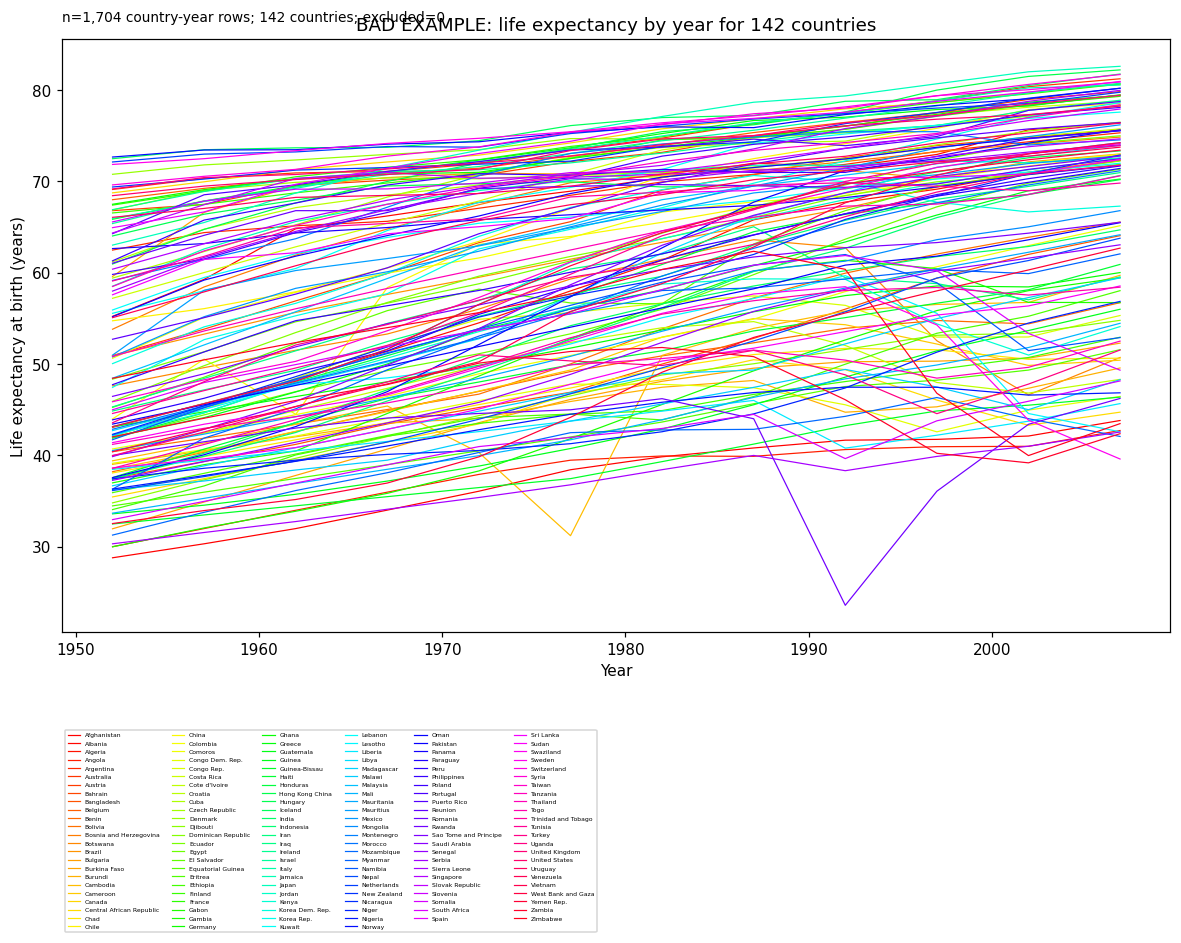

In [2]:
gap=pd.read_csv(DATA/'gapminder.csv')
fig,ax=plt.subplots(figsize=(13,7))
for i,(country,d) in enumerate(gap.groupby('country')):
    ax.plot(d.year,d.lifeExp,color=plt.colormaps['hsv'](i/142),lw=.8,label=country)
ax.set(title='BAD EXAMPLE: life expectancy by year for 142 countries',xlabel='Year',ylabel='Life expectancy at birth (years)')
ax.legend(ncol=6,fontsize=4,loc='upper left',bbox_to_anchor=(0,-.16))
ax.text(0,1.03,'n=1,704 country-year rows; 142 countries; excluded=0',transform=ax.transAxes,fontsize=9)
save(fig,'task5_spaghetti_bad.png');plt.show()


**Reader question:** how did Pakistan’s life expectancy change from 1952 to 2007?

**What the eye does:** continuity and connection let the eye trace a line, but 142 overlapping lines and rainbow hues prevent reliable selection. Position carries year and life expectancy correctly; arbitrary hue carries nominal country identity inefficiently. The enormous legend forces repeated lookup. Every row is kept; clutter is a design problem, not missing data.

| Audit row | Before: spaghetti | After: focused redesign |
|---|---|---|
| Preattentive | Many nominal hues compete; position is useful | One accent line selects Pakistan; aligned y-position carries years of life |
| Pop-out | Many saturated series; none consistently answers the question | Exactly one highlighted series, matching title |
| Gestalt | Connection traces each line but crossings compete | **Connection** groups Pakistan’s 12 observations as a trajectory |
| Cognitive load | Intrinsic: 142 histories. Extraneous: 142 hues, crowded crossings, 142 legend entries. Germane: axes, scale, lines, units, coverage | Intrinsic: selected trajectory plus background range. Extraneous: removed legend, rainbow and heavy frame. Germane: scale, title, direct label, endpoint values, coverage |
| Channels | Year=x position; life expectancy=y position (high rank); country=hue (nominal but excessive) | Year=x; life expectancy=y on a common scale (highest rank); Pakistan=accent + direct text + endpoint labels |
| Working memory | Potentially 142 legend-to-line associations | About four useful chunks: highlighted path, starting value, ending value, grey comparison context |

The audit is written before reconstruction; the after column records the completed design’s intended behavior. A chunk count is a design heuristic, not a measured memory score.

Increase = 22.047 years. All countries and all years retained.


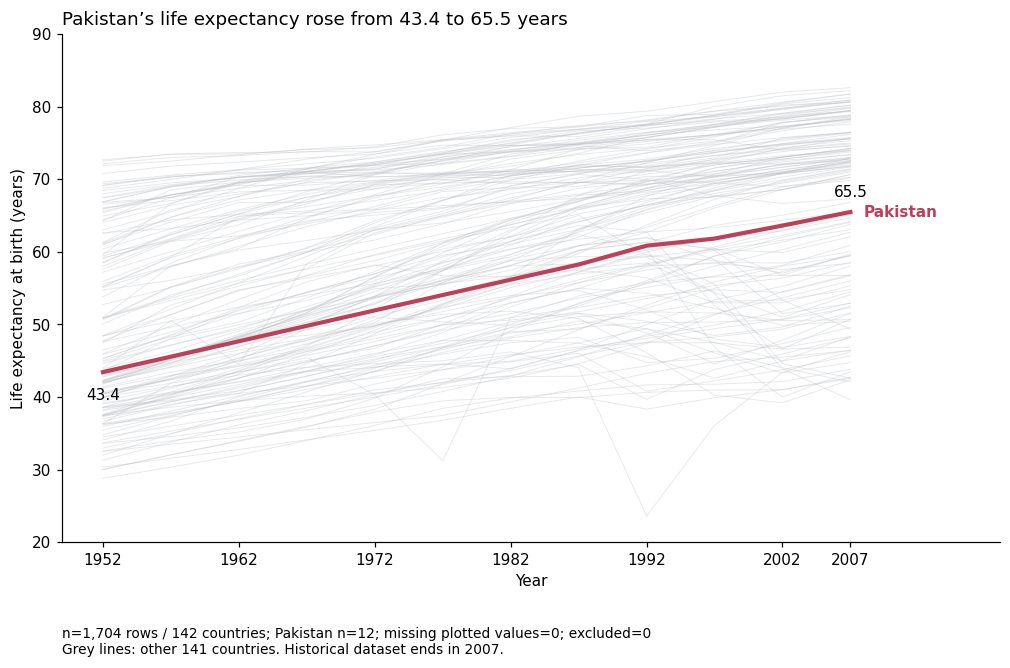

In [3]:
pak=gap[gap.country.eq('Pakistan')].sort_values('year')
start_value=pak.lifeExp.iloc[0];end_value=pak.lifeExp.iloc[-1]
fig,ax=plt.subplots(figsize=(11,6))
for country,d in gap.groupby('country'):
    if country!='Pakistan':ax.plot(d.year,d.lifeExp,color=GREY,lw=.6,alpha=.35)
ax.plot(pak.year,pak.lifeExp,color=ACCENT,lw=2.7)
ax.text(2008,end_value,'Pakistan',va='center',fontweight='bold',color=ACCENT)
ax.annotate(f'{start_value:.1f}',(1952,start_value),xytext=(0,-18),textcoords='offset points',ha='center')
ax.annotate(f'{end_value:.1f}',(2007,end_value),xytext=(0,10),textcoords='offset points',ha='center')
ax.set_title(f'Pakistan’s life expectancy rose from {start_value:.1f} to {end_value:.1f} years',loc='left')
ax.set(xlabel='Year',ylabel='Life expectancy at birth (years)',xlim=(1949,2018),ylim=(20,90))
ax.set_xticks([1952,1962,1972,1982,1992,2002,2007]);clean(ax)
ax.text(0,-.22,'n=1,704 rows / 142 countries; Pakistan n=12; missing plotted values=0; excluded=0\nGrey lines: other 141 countries. Historical dataset ends in 2007.',transform=ax.transAxes,fontsize=9)
save(fig,'perception_redesign.png');plt.show()
print(f'Increase = {end_value-start_value:.3f} years. All countries and all years retained.')


**What the eye does:** the single accent **series** is the pop-out element, carrying the finding in the title. It is one connected path rather than 12 separate highlighted dots. Connection is the named grouping principle. Year and life expectancy use aligned position, the highest-ranking quantitative channel; country identity is carried by the direct label, not colour alone. Endpoint text saves subtraction and scale lookup. Grey keeps the other histories available as context. No bars or dual axes are used.

**Ink count and cost:** removed 142 legend text entries and 142 legend handles, replaced 142 arbitrary hues with grey context plus one accent, and removed top/right spines. Retained 142 data lines and axes, added a direct country label and two endpoint values because those aid interpretation. Greying context makes individual other countries and between-country rankings harder to identify; the redesign focuses attention rather than answering all questions. A causal explanation for Pakistan’s rise cannot be inferred from this descriptive chart.

**Human test:** show only the redesign to a reader unfamiliar with the dataset and ask “In one sentence, what does this chart show?” Record exactly what they say. Compare with the title; if they confuse grey context with Pakistan or infer causation, note the misunderstanding and the next change. No real answer has been supplied, so comprehension validation is pending.

In [4]:
import ipywidgets as widgets, json
reader=widgets.Text(description='Reader:');sentence=widgets.Textarea(description='Verbatim:')
match=widgets.Dropdown(options=['Pending','Yes','No'],description='Matches?')
revision=widgets.Textarea(description='Next change:');button=widgets.Button(description='Save real response');out=widgets.Output()
def record_capstone(_):
    with out:
        out.clear_output()
        if not reader.value.strip() or not sentence.value.strip() or match.value=='Pending':print('Enter the real reader, exact sentence, and assessment.');return
        answer={'participant':reader.value.strip(),'prompt':'In one sentence, what does this chart show?',
                'verbatim_sentence':sentence.value,'matches_title':match.value,'next_change':revision.value}
        (RESULTS/'capstone_reader.json').write_text(json.dumps(answer,indent=2),encoding='utf-8');display(answer)
button.on_click(record_capstone);display(widgets.VBox([reader,sentence,match,revision,button,out]))
if (RESULTS/'capstone_reader.json').exists():display(json.loads((RESULTS/'capstone_reader.json').read_text()))
else:print('PENDING: no reader sentence recorded.')


PENDING: no reader sentence recorded.


**Self-audit:** OO chart API ✓; one accent series ✓; connection named ✓; highest-ranked quantitative position ✓; load classification ✓; approx. four focused chunks ✓; redundant text identity ✓; grey context ✓; n/missing/exclusions on figure ✓; finding title ✓; 300 DPI tight export ✓. **Real-reader sentence: pending**, so the final human-check criterion is not yet met.